# Barrido del tamaño de ventana con GRU, DS2OS

Entrena el autoencoder GRU con distintos tamaños de ventana W y registra el número de ventanas de entrenamiento, la memoria que ocupan, el tiempo de entrenamiento y el AUC.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

In [2]:
DATA_PATH = Path.home() / ".cache/kagglehub/datasets/libamariyam/ds2os-dataset/versions/1/DS2OS.csv"
df = pd.read_csv(DATA_PATH)
df['accessedNodeType'] = df['accessedNodeType'].fillna('missing')
df['value'] = df['value'].replace({'true': 1, 'false': 0, 'twenty': 20, 'none': 0})
df['value'] = pd.to_numeric(df['value'], errors='coerce').fillna(0)

# Ventanas por dispositivo (sourceID), ordenadas por timestamp
df['group'] = df['sourceID']
df['order'] = df['timestamp']
df['is_attack'] = (df['normality'] != 'normal').astype(int)
CAT_COLS = ['sourceID', 'sourceAddress', 'sourceType', 'sourceLocation',
            'destinationServiceAddress', 'destinationServiceType', 'destinationLocation',
            'accessedNodeAddress', 'accessedNodeType', 'operation']
X = pd.get_dummies(df.drop(columns=['normality', 'timestamp', 'group', 'order', 'is_attack']), columns=CAT_COLS)
meta = df[['group', 'order', 'is_attack']]
print(X.shape)

(357952, 505)


In [3]:
def build_windows(X, meta, W, stride=1):
    meta = meta.copy()
    meta['pos'] = meta.groupby('group').cumcount()
    meta['grp_size'] = meta.groupby('group')['group'].transform('size')
    order_idx = meta.sort_values(['group', 'order']).index
    X = X.loc[order_idx].reset_index(drop=True)
    meta = meta.loc[order_idx].reset_index(drop=True)

    train_mask = (meta['pos'] < (0.8 * meta['grp_size'])).to_numpy()
    scaler = MinMaxScaler().fit(X.to_numpy()[train_mask])
    Xs = scaler.transform(X.to_numpy()).astype('float32')
    attack_arr = meta['is_attack'].to_numpy()
    group_arr = meta['group'].to_numpy()

    train_windows, test_windows, test_labels = [], [], []
    for gid in pd.unique(group_arr):
        sel = np.where(group_arr == gid)[0]
        is_train = train_mask[sel]
        train_idxs = sel[is_train]
        test_idxs = sel[~is_train]

        n_tr = len(train_idxs) - W + 1
        if n_tr > 0:
            attack_tr = attack_arr[train_idxs]
            cums = np.concatenate([[0], np.cumsum(attack_tr)])
            window_sums = cums[W:] - cums[:-W]
            for i in np.where(window_sums == 0)[0][::stride]:
                train_windows.append(Xs[train_idxs[i:i + W]])

        n_te = len(test_idxs) - W + 1
        if n_te > 0:
            attack_te = attack_arr[test_idxs]
            cums = np.concatenate([[0], np.cumsum(attack_te)])
            window_sums = cums[W:] - cums[:-W]
            for i in range(0, n_te, stride):
                test_windows.append(Xs[test_idxs[i:i + W]])
                test_labels.append(int(window_sums[i] > 0))

    X_train_w = np.array(train_windows) if train_windows else np.empty((0, W, X.shape[1]))
    X_test_w = np.array(test_windows) if test_windows else np.empty((0, W, X.shape[1]))
    y_test_w = np.array(test_labels)
    return X_train_w, X_test_w, y_test_w

In [4]:
DATASET_KEY = 'ds2os'
STRIDE = 5
TITLE = 'Barrido de W -- GRU, DS2OS'
EPOCHS = 40
PATIENCE = 8

In [5]:
CSV_PATH = Path.cwd() / f"_barrido_w_checkpoint_{DATASET_KEY}.csv"
results = []

def run_one(W, stride):
    t0 = time.perf_counter()
    X_train_w, X_test_w, y_test_w = build_windows(X, meta, W, stride=stride)
    build_time = time.perf_counter() - t0

    if X_train_w.shape[0] < 10 or X_test_w.shape[0] < 10:
        row = {'W': W, 'ventanas_train': X_train_w.shape[0], 'ventanas_test': X_test_w.shape[0],
               'memoria_train_MB': round(X_train_w.nbytes / 1e6, 2), 'epocas': None,
               'tiempo_construccion_s': round(build_time, 1), 'tiempo_entrenamiento_s': None,
               'roc_auc': None}
        print(f"W={W}: ventanas insuficientes (train={X_train_w.shape[0]}, test={X_test_w.shape[0]}) -> se omite")
    else:
        input_dim = X_train_w.shape[2]
        bottleneck = 16
        tf.keras.utils.set_random_seed(SEED)

        inputs = keras.Input(shape=(W, input_dim))
        x = layers.GRU(32, return_sequences=True)(inputs)
        x = layers.GRU(bottleneck, return_sequences=False)(x)
        x = layers.RepeatVector(W)(x)
        x = layers.GRU(bottleneck, return_sequences=True)(x)
        x = layers.GRU(32, return_sequences=True)(x)
        outputs = layers.TimeDistributed(layers.Dense(input_dim, activation='sigmoid'))(x)

        autoencoder = keras.Model(inputs, outputs)
        autoencoder.compile(optimizer='adam', loss='mse')

        t1 = time.perf_counter()
        history = autoencoder.fit(
            X_train_w, X_train_w,
            epochs=EPOCHS, batch_size=64, validation_split=0.1,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)],
            verbose=0,
        )
        train_time = time.perf_counter() - t1

        def reconstruction_error(Xw):
            return np.mean(np.square(Xw - autoencoder.predict(Xw, verbose=0)), axis=(1, 2))

        err_test = reconstruction_error(X_test_w)
        auc = roc_auc_score(y_test_w, err_test)
        mem_mb = X_train_w.nbytes / 1e6

        row = {
            'W': W,
            'ventanas_train': X_train_w.shape[0],
            'ventanas_test': X_test_w.shape[0],
            'memoria_train_MB': round(mem_mb, 2),
            'epocas': len(history.history['loss']),
            'tiempo_construccion_s': round(build_time, 1),
            'tiempo_entrenamiento_s': round(train_time, 1),
            'roc_auc': round(float(auc), 4),
        }
        print(f"W={W}: ventanas_train={X_train_w.shape[0]}, memoria={mem_mb:.1f}MB, "
              f"epocas={len(history.history['loss'])}, tiempo={train_time:.1f}s, AUC={auc:.4f}")

        del autoencoder
        tf.keras.backend.clear_session()

    results.append(row)
    pd.DataFrame(results).to_csv(CSV_PATH, index=False)
    return row

In [6]:
run_one(3, STRIDE)

W=3: ventanas_train=55287, memoria=335.0MB, epocas=10, tiempo=88.7s, AUC=0.9238


{'W': 3,
 'ventanas_train': 55287,
 'ventanas_test': 14316,
 'memoria_train_MB': 335.04,
 'epocas': 10,
 'tiempo_construccion_s': 14.7,
 'tiempo_entrenamiento_s': 88.7,
 'roc_auc': 0.9238}

In [7]:
run_one(5, STRIDE)

W=5: ventanas_train=55130, memoria=556.8MB, epocas=21, tiempo=275.7s, AUC=0.9208


{'W': 5,
 'ventanas_train': 55130,
 'ventanas_test': 14275,
 'memoria_train_MB': 556.81,
 'epocas': 21,
 'tiempo_construccion_s': 15.5,
 'tiempo_entrenamiento_s': 275.7,
 'roc_auc': 0.9208}

In [8]:
run_one(10, STRIDE)

W=10: ventanas_train=54985, memoria=1110.7MB, epocas=20, tiempo=470.1s, AUC=0.9444


{'W': 10,
 'ventanas_train': 54985,
 'ventanas_test': 14195,
 'memoria_train_MB': 1110.7,
 'epocas': 20,
 'tiempo_construccion_s': 20.5,
 'tiempo_entrenamiento_s': 470.1,
 'roc_auc': 0.9444}

In [9]:
run_one(15, STRIDE)

W=15: ventanas_train=54883, memoria=1663.0MB, epocas=26, tiempo=892.3s, AUC=0.9450


{'W': 15,
 'ventanas_train': 54883,
 'ventanas_test': 14124,
 'memoria_train_MB': 1662.95,
 'epocas': 26,
 'tiempo_construccion_s': 24.2,
 'tiempo_entrenamiento_s': 892.3,
 'roc_auc': 0.945}

In [10]:
run_one(20, STRIDE)

W=20: ventanas_train=54781, memoria=2213.2MB, epocas=12, tiempo=452.2s, AUC=0.9401


{'W': 20,
 'ventanas_train': 54781,
 'ventanas_test': 14067,
 'memoria_train_MB': 2213.15,
 'epocas': 12,
 'tiempo_construccion_s': 45.4,
 'tiempo_entrenamiento_s': 452.2,
 'roc_auc': 0.9401}

In [11]:
run_one(30, STRIDE)

W=30: ventanas_train=54583, memoria=3307.7MB, epocas=13, tiempo=787.3s, AUC=0.9448


{'W': 30,
 'ventanas_train': 54583,
 'ventanas_test': 13954,
 'memoria_train_MB': 3307.73,
 'epocas': 13,
 'tiempo_construccion_s': 28.9,
 'tiempo_entrenamiento_s': 787.3,
 'roc_auc': 0.9448}

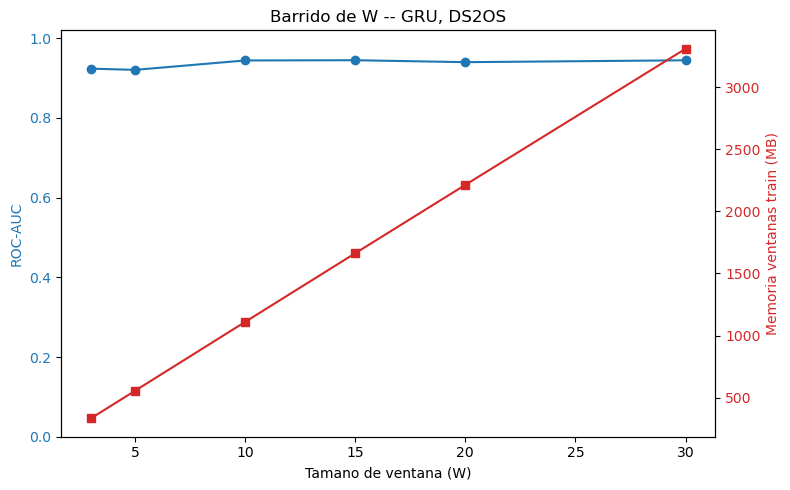

,W,ventanas_train,ventanas_test,memoria_train_MB,epocas,tiempo_construccion_s,tiempo_entrenamiento_s,roc_auc
0,3,55287,14316,335.04,10,14.7,88.7,0.9238
1,5,55130,14275,556.81,21,15.5,275.7,0.9208
2,10,54985,14195,1110.70,20,20.5,470.1,0.9444
3,15,54883,14124,1662.95,26,24.2,892.3,0.9450
4,20,54781,14067,2213.15,12,45.4,452.2,0.9401
5,30,54583,13954,3307.73,13,28.9,787.3,0.9448


In [12]:
import matplotlib.pyplot as plt

df_res = pd.DataFrame(results)
df_plot = df_res.dropna(subset=['roc_auc'])

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.set_xlabel('Tamano de ventana (W)')
ax1.set_ylabel('ROC-AUC', color='tab:blue')
ax1.plot(df_plot['W'], df_plot['roc_auc'], marker='o', color='tab:blue', label='ROC-AUC')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_ylim(0, 1.02)

ax2 = ax1.twinx()
ax2.set_ylabel('Memoria ventanas train (MB)', color='tab:red')
ax2.plot(df_plot['W'], df_plot['memoria_train_MB'], marker='s', color='tab:red', label='Memoria (MB)')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title(TITLE)
fig.tight_layout()
plt.show()
df_res

## Resultado

| W | ventanas train | memoria | AUC |
|---|---|---|---|
| 3 | 55287 | 335 MB | 0.9238 |
| 5 | 55130 | 557 MB | 0.9208 |
| 10 (elegido) | 54985 | 1.111 MB | 0.9444 |
| 15 | 54883 | 1.663 MB | 0.9450 |
| 20 | 54781 | 2.213 MB | 0.9401 |
| 30 | 54583 | 3.308 MB | 0.9448 |

El AUC deja de mejorar a partir de W = 10, mientras que la memoria sigue creciendo. Se elige W = 10.